In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("shivamb/netflix-shows")

print("Path to dataset files:", path)

c:\Users\usifa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\usifa\.cache\kagglehub\datasets\shivamb\netflix-shows\versions\5


In [2]:
import os
import pandas as pd
import numpy as np
import seaborn as sns

file_path = os.path.join(path, "netflix_titles.csv")

df = pd.read_csv(file_path)

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
df.info()
df.isna().sum()/df.shape[0]

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 3.9 MB


show_id         0.000000
type            0.000000
title           0.000000
director        0.299080
cast            0.093675
country         0.094357
date_added      0.001135
release_year    0.000000
rating          0.000454
duration        0.000341
listed_in       0.000000
description     0.000000
dtype: float64

In [4]:
df.dtypes

show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object

In [5]:
df['date_added'] = df['date_added'].str.strip()
df.date_added = pd.to_datetime(df.date_added)
df['year_added'] = df['date_added'].dt.year
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021.0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021.0
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021.0
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021.0


In [6]:
df['year_added'] = df['year_added'].astype('Int64')
df.dtypes

show_id                    str
type                       str
title                      str
director                   str
cast                       str
country                    str
date_added      datetime64[us]
release_year             int64
rating                     str
duration                   str
listed_in                  str
description                str
year_added               Int64
dtype: object

In [7]:
df.duplicated().any()

np.False_

In [8]:
top_10_actors = df['cast'].str.split(',').explode().value_counts().head(10)
print(top_10_actors)
print("================================")
top_10_Categories = df['listed_in'].str.split(',').explode().value_counts().head(10)
print(top_10_Categories)


cast
 Anupam Kher         39
 Rupa Bhimani        31
 Takahiro Sakurai    30
 Julie Tejwani       28
 Om Puri             27
 Rajesh Kava         26
Shah Rukh Khan       26
 Andrea Libman       25
 Yuki Kaji           25
 Boman Irani         25
Name: count, dtype: int64
listed_in
 International Movies     2624
Dramas                    1600
Comedies                  1210
Action & Adventure         859
Documentaries              829
 Dramas                    827
International TV Shows     774
 Independent Movies        736
 TV Dramas                 696
 Romantic Movies           613
Name: count, dtype: int64


In [9]:
df.country.unique()

<ArrowStringArray>
[                                                        'United States',
                                                          'South Africa',
                                                                     nan,
                                                                 'India',
 'United States, Ghana, Burkina Faso, United Kingdom, Germany, Ethiopia',
                                                        'United Kingdom',
                                               'Germany, Czech Republic',
                                                                'Mexico',
                                                                'Turkey',
                                                             'Australia',
 ...
                        'Germany, United States, United Kingdom, Canada',
          'Canada, India, Thailand, United States, United Arab Emirates',
                             'United States, East Germany, West Germany',
              

In [10]:
top_10_Countries = df['country'].str.split(',').explode().value_counts().head(10)
print(top_10_Countries)


country
United States     3211
India             1008
United Kingdom     628
 United States     479
Canada             271
Japan              259
France             212
South Korea        211
 France            181
Spain              181
Name: count, dtype: int64


In [11]:
# Data Quality Assessment

print("Dataset Shape:", df.shape)

print("\n--- Data Types ---")
display(df.dtypes)

print("\n--- Missing Values ---")

missing_report = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (
        df.isnull().mean() * 100
    ).round(2)
})

display(
    missing_report.sort_values(
        by='Missing_Percentage',
        ascending=False
    )
)

print("\n--- Duplicate Rows ---")
print(df.duplicated().sum())

print("\n--- Duplicate IDs ---")
print(df['show_id'].duplicated().sum())

print("\n--- Unique Values ---")
display(df.nunique())

Dataset Shape: (8807, 13)

--- Data Types ---


show_id                    str
type                       str
title                      str
director                   str
cast                       str
country                    str
date_added      datetime64[us]
release_year             int64
rating                     str
duration                   str
listed_in                  str
description                str
year_added               Int64
dtype: object


--- Missing Values ---


,Missing_Count,Missing_Percentage
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
year_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
title,0,0.00
type,0,0.00



--- Duplicate Rows ---
0

--- Duplicate IDs ---
0

--- Unique Values ---


show_id         8807
type               2
title           8807
director        4528
cast            7692
country          748
date_added      1714
release_year      74
rating            17
duration         220
listed_in        514
description     8775
year_added        14
dtype: int64

In [14]:
df['director'] = df['director'].fillna('Unknown')
text_cols = df.select_dtypes(include=['object', 'string']).columns

for col in text_cols:
    df[col] = df[col].str.strip()


In [15]:
columns = ['country', 'cast', 'listed_in']

for col in columns:
    print(f"\n--- {col} ---")
    display(df[col].dropna().head(10))


--- country ---


0                                         United States
1                                          South Africa
4                                                 India
7     United States, Ghana, Burkina Faso, United Kin...
8                                        United Kingdom
9                                         United States
12                              Germany, Czech Republic
15                                        United States
17                                               Mexico
21                                               Turkey
Name: country, dtype: str


--- cast ---


1     Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...
2     Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...
4     Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...
5     Kate Siegel, Zach Gilford, Hamish Linklater, H...
6     Vanessa Hudgens, Kimiko Glenn, James Marsden, ...
7     Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...
8     Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...
9     Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...
11    Sukollawat Kanarot, Sushar Manaying, Pavarit M...
12    Luna Wedler, Jannis Niewöhner, Milan Peschel, ...
Name: cast, dtype: str


--- listed_in ---


0                                        Documentaries
1      International TV Shows, TV Dramas, TV Mysteries
2    Crime TV Shows, International TV Shows, TV Act...
3                               Docuseries, Reality TV
4    International TV Shows, Romantic TV Shows, TV ...
5                   TV Dramas, TV Horror, TV Mysteries
6                             Children & Family Movies
7     Dramas, Independent Movies, International Movies
8                         British TV Shows, Reality TV
9                                     Comedies, Dramas
Name: listed_in, dtype: str

In [16]:
print("Duration Unique Values:")

display(
    df['duration'].value_counts().head(20)
)

print("\nMissing Duration Rows:")

display(
    df[df['duration'].isna()][
        ['show_id', 'title', 'type', 'duration']
    ]
)

Duration Unique Values:


duration
1 Season     1793
2 Seasons     425
3 Seasons     199
90 min        152
94 min        146
97 min        146
93 min        146
91 min        144
95 min        137
96 min        130
92 min        129
102 min       122
98 min        120
99 min        118
88 min        116
101 min       116
103 min       114
106 min       111
100 min       108
89 min        106
Name: count, dtype: int64


Missing Duration Rows:


,show_id,title,type,duration
5541,s5542,Louis C.K. 2017,Movie,NaN
5794,s5795,Louis C.K.: Hilarious,Movie,NaN
5813,s5814,Louis C.K.: Live at the Comedy Store,Movie,NaN


### Louis C.K. Movies is the only without duration

In [44]:
display(
    df[df['director'] == 'Unknown'][
        ['show_id', 'title', 'type', 'country']
    ].head(10)
)
display(len(df[(df['director'] == 'Unknown') & (df['type'] == 'TV Show')]) / len(df[df['director'] == 'Unknown'])) # from the total unknown directors, 92% are TV Shows and 8% are Movies
display(len(df[(df['director'] == 'Unknown') & (df['type'] == 'TV Show')]) / len(df[df['type'] == 'TV Show'])) #91% of the total TV Shows are from unknown directors


,show_id,title,type,country
1,s2,Blood & Water,TV Show,South Africa
3,s4,Jailbirds New Orleans,TV Show,NaN
4,s5,Kota Factory,TV Show,India
10,s11,"Vendetta: Truth, Lies and The Mafia",TV Show,NaN
14,s15,Crime Stories: India Detectives,TV Show,NaN
15,s16,Dear White People,TV Show,United States
17,s18,Falsa identidad,TV Show,Mexico
19,s20,Jaguar,TV Show,NaN
21,s22,Resurrection: Ertugrul,TV Show,Turkey
25,s26,Love on the Spectrum,TV Show,Australia


0.9286256643887624

0.914050822122571

### Most TV shows (91%) got unkhnow director

In [54]:
duration_split = df['duration'].str.split(' ', expand=True)
display(duration_split.head(10))
df['duration_value'] = pd.to_numeric(
    duration_split[0],
    errors='coerce'
)
df['duration_unit'] = duration_split[1]
display(
    df[['duration', 'duration_value', 'duration_unit']].head(15)
)


,0,1
0,90,min
1,2,Seasons
2,1,Season
3,1,Season
4,2,Seasons
5,1,Season
6,91,min
7,125,min
8,9,Seasons
9,104,min


,duration,duration_value,duration_unit
0,90 min,90.0,min
1,2 Seasons,2.0,Seasons
2,1 Season,1.0,Season
3,1 Season,1.0,Season
4,2 Seasons,2.0,Seasons
5,1 Season,1.0,Season
6,91 min,91.0,min
7,125 min,125.0,min
8,9 Seasons,9.0,Seasons
9,104 min,104.0,min


In [58]:
print("Duration Units Distribution:")

display(df['duration_unit'].value_counts(dropna=False))

wrong_movies = df[
    (df['type'] == 'Movie') &
    (df['duration_unit'].isin(['Season', 'Seasons']))
]


wrong_tv_shows = df[
    (df['type'] == 'TV Show') &
    (df['duration_unit'] == 'min')
]

print("Movies with Seasons:", len(wrong_movies))
print("TV Shows with Minutes:", len(wrong_tv_shows))

display(
    df[df['duration_value'].isna()][
        ['title', 'type', 'duration',
         'duration_value', 'duration_unit']
    ]
)

Duration Units Distribution:


duration_unit
min        6128
Season     1793
Seasons     883
NaN           3
Name: count, dtype: int64

Movies with Seasons: 0
TV Shows with Minutes: 0


,title,type,duration,duration_value,duration_unit
5541,Louis C.K. 2017,Movie,NaN,NaN,NaN
5794,Louis C.K.: Hilarious,Movie,NaN,NaN,NaN
5813,Louis C.K.: Live at the Comedy Store,Movie,NaN,NaN,NaN


In [65]:
def split_explode_column(df, column):

    result = df[['show_id', column]].dropna().copy()

    result[column] = result[column].str.split(',')

    result = result.explode(column)

    result[column] = result[column].str.strip()

    return result

In [66]:
countries_df = split_explode_column(df, 'country')

cast_df = split_explode_column(df, 'cast')

genres_df = split_explode_column(df, 'listed_in')

In [67]:
for name, data in {
    'Countries': countries_df,
    'Cast': cast_df,
    'Genres': genres_df
}.items():

    print(f"\n--- {name} ---")
    print("Rows:", len(data))
    print("Unique Values:", data.iloc[:, 1].nunique())

    display(data.head())


--- Countries ---
Rows: 10019
Unique Values: 123


,show_id,country
0,s1,United States
1,s2,South Africa
4,s5,India
7,s8,United States
7,s8,Ghana



--- Cast ---
Rows: 64126
Unique Values: 36439


,show_id,cast
1,s2,Ama Qamata
1,s2,Khosi Ngema
1,s2,Gail Mabalane
1,s2,Thabang Molaba
1,s2,Dillon Windvogel



--- Genres ---
Rows: 19323
Unique Values: 42


,show_id,listed_in
0,s1,Documentaries
1,s2,International TV Shows
1,s2,TV Dramas
1,s2,TV Mysteries
2,s3,Crime TV Shows


In [72]:
top_genres = genres_df['listed_in'].value_counts().head(10)

display(top_genres)



listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

In [71]:
genre_counts = (
    genres_df.groupby('listed_in')['show_id']
    .nunique()
    .sort_values(ascending=False)
)

display(genre_counts.head(10))

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: show_id, dtype: int64

In [79]:
top_actors = cast_df['cast'].value_counts().head(10)

display(top_actors)

top_countries = (
    countries_df.groupby('country')['show_id']
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

display(top_countries)


cast
Anupam Kher         43
Shah Rukh Khan      35
Julie Tejwani       33
Naseeruddin Shah    32
Takahiro Sakurai    32
Rupa Bhimani        31
Akshay Kumar        30
Om Puri             30
Yuki Kaji           29
Amitabh Bachchan    28
Name: count, dtype: int64

country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: show_id, dtype: int64

In [82]:
countries_df = df[
    ['show_id', 'type', 'country']
].dropna().copy()

countries_df['country'] = (
    countries_df['country'].str.split(',')
)

countries_df = countries_df.explode('country')

countries_df['country'] = (
    countries_df['country'].str.strip()
)

In [83]:
country_type_analysis = (
    countries_df.groupby(['country', 'type'])['show_id']
    .nunique()
    .unstack(fill_value=0)
)

country_type_analysis['Total'] = (
    country_type_analysis.sum(axis=1)
)

country_type_analysis = (
    country_type_analysis.sort_values(
        'Total', ascending=False
    )
)

display(country_type_analysis.head(10))

type,Movie,TV Show,Total
country,,,
United States,2752,938,3690
India,962,84,1046
United Kingdom,534,272,806
Canada,319,126,445
France,303,90,393
Japan,119,199,318
Spain,171,61,232
South Korea,61,170,231
Germany,182,44,226


In [85]:
yearly_content = (
    df.groupby(['year_added', 'type'])['show_id']
    .nunique()
    .unstack(fill_value=0)
)

display(yearly_content.tail(15))

type,Movie,TV Show
year_added,,
2008,1,1
2009,2,0
2010,1,0
2011,13,0
2012,3,0
2013,6,5
2014,19,5
2015,56,26
2016,253,176


In [86]:
yearly_content['Total'] = yearly_content.sum(axis=1)

display(yearly_content.tail(15))

type,Movie,TV Show,Total
year_added,,,
2008,1,1,2
2009,2,0,2
2010,1,0,1
2011,13,0,13
2012,3,0,3
2013,6,5,11
2014,19,5,24
2015,56,26,82
2016,253,176,429


In [87]:
top_years = yearly_content.sort_values(
    'Total',
    ascending=False
)

display(top_years.head(10))

type,Movie,TV Show,Total
year_added,,,
2019,1424,592,2016
2020,1284,595,1879
2018,1237,412,1649
2021,993,505,1498
2017,839,349,1188
2016,253,176,429
2015,56,26,82
2014,19,5,24
2011,13,0,13


In [92]:
yearly_content['Previous_Year_Total'] = yearly_content['Total'].shift(1)

yearly_content['Yearly_Change'] = (
    yearly_content['Total'] - yearly_content['Previous_Year_Total']
)

yearly_content['Growth_Rate_%'] = ((
    yearly_content['Yearly_Change'] /
    yearly_content['Previous_Year_Total']
) * 100).round(2)

display(yearly_content.tail(15))

type,Movie,TV Show,Total,Previous_Year_Total,Yearly_Change,Growth_Rate_%
year_added,,,,,,
2008,1,1,2,NaN,NaN,NaN
2009,2,0,2,2.0,0.0,0.00
2010,1,0,1,2.0,-1.0,-50.00
2011,13,0,13,1.0,12.0,1200.00
2012,3,0,3,13.0,-10.0,-76.92
2013,6,5,11,3.0,8.0,266.67
2014,19,5,24,11.0,13.0,118.18
2015,56,26,82,24.0,58.0,241.67
2016,253,176,429,82.0,347.0,423.17


In [93]:
rating_analysis = (
    df.groupby(['rating', 'type'])['show_id']
    .nunique()
    .unstack(fill_value=0)
)

display(rating_analysis.sort_values(
    by='Movie',
    ascending=False
))

type,Movie,TV Show
rating,,
TV-MA,2062,1145
TV-14,1427,733
R,797,2
TV-PG,540,323
PG-13,490,0
PG,287,0
TV-Y7,139,195
TV-Y,131,176
TV-G,126,94


In [94]:
display(
    df[df['rating'].str.contains('min', na=False)][
        ['title', 'type', 'rating', 'duration']
    ]
)

,title,type,rating,duration
5541,Louis C.K. 2017,Movie,74 min,NaN
5794,Louis C.K.: Hilarious,Movie,84 min,NaN
5813,Louis C.K.: Live at the Comedy Store,Movie,66 min,NaN


In [ ]:
df.loc[
    df['rating'].str.contains('min', na=False),
    'rating'
] = np.nan

display(df['rating'].value_counts(dropna=False))

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
NaN            7
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

In [96]:
movie_duration = df[df['type'] == 'Movie']['duration_value']

tv_duration = df[df['type'] == 'TV Show']['duration_value']

print("Movie Duration:")
display(movie_duration.describe())

print("TV Show Seasons:")
display(tv_duration.describe())

Movie Duration:


count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_value, dtype: float64

TV Show Seasons:


count    2676.000000
mean        1.764948
std         1.582752
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: duration_value, dtype: float64

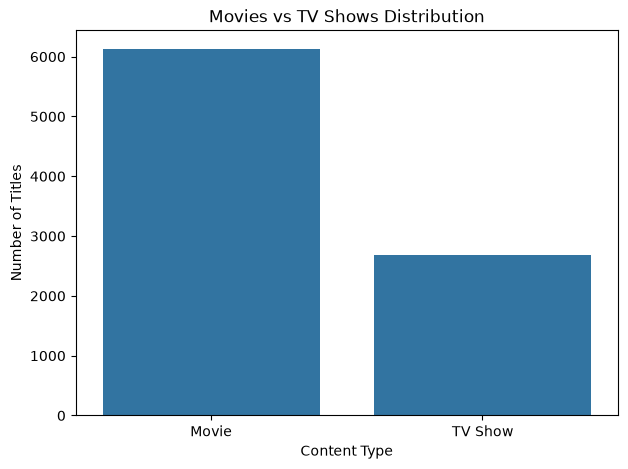

In [97]:
import matplotlib.pyplot as plt
import seaborn as sns

content_counts = df['type'].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(
    x=content_counts.index,
    y=content_counts.values
)

plt.title('Movies vs TV Shows Distribution')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.show()

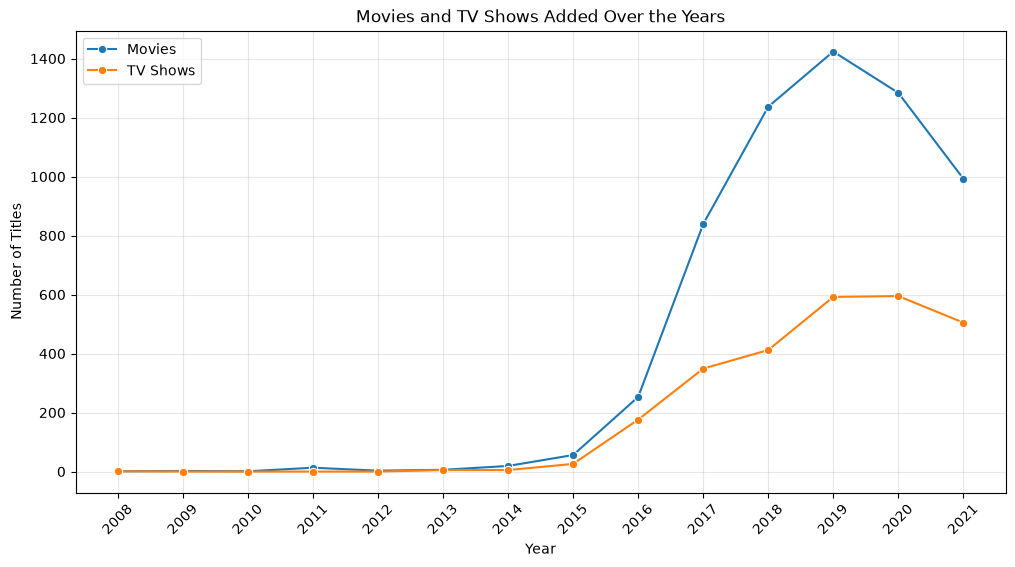

In [98]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=yearly_content,
    x=yearly_content.index,
    y='Movie',
    label='Movies',
    marker='o'
)

sns.lineplot(
    data=yearly_content,
    x=yearly_content.index,
    y='TV Show',
    label='TV Shows',
    marker='o'
)

plt.title('Movies and TV Shows Added Over the Years')
plt.xlabel('Year')
plt.ylabel('Number of Titles')
plt.xticks(yearly_content.index, rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

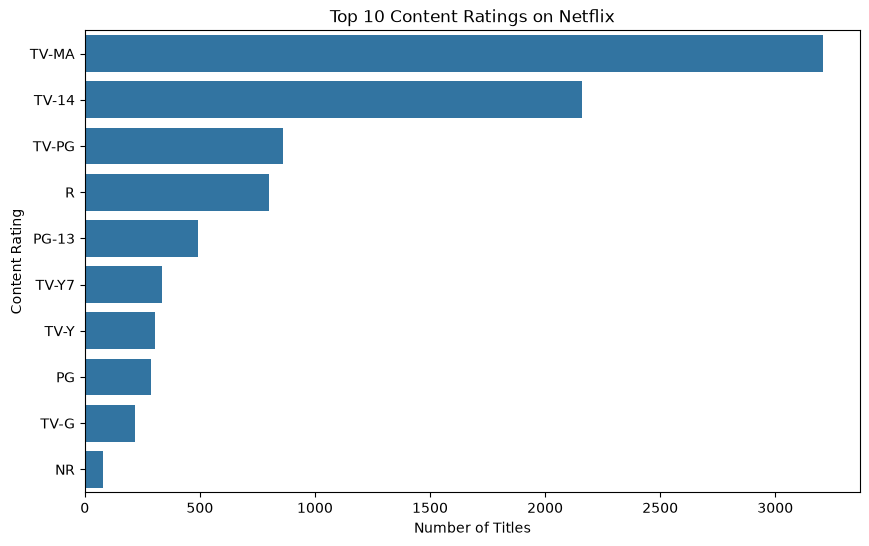

In [99]:
top_ratings = df['rating'].value_counts().head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_ratings.values,
    y=top_ratings.index
)

plt.title('Top 10 Content Ratings on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Content Rating')
plt.show()

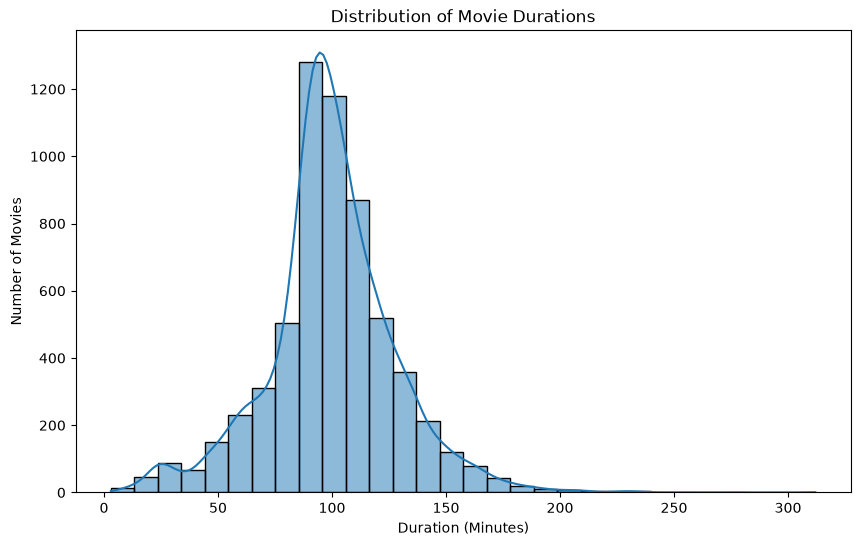

In [100]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df[df['type'] == 'Movie'],
    x='duration_value',
    bins=30,
    kde=True
)

plt.title('Distribution of Movie Durations')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Number of Movies')
plt.show()


# Final Insights & Conclusion

## Key Findings

1. Movies represent the largest share of content in the Netflix dataset compared to TV Shows.

2. 2019 recorded the highest content additions, with 2,016 titles.

3. Content additions declined in 2020 and 2021 compared to 2019.

4. TV-MA and TV-14 are the most common content ratings across the dataset.

5. Movies have an average duration of approximately 100 minutes, while TV Shows have an average of approximately 1.76 seasons.

6. The median number of seasons is one, indicating that at least half of the recorded TV Shows have one season or fewer.

## Conclusion

The analysis provides an overview of Netflix's content distribution, ratings, duration patterns, and yearly content additions.

The dataset shows a clear preference toward Movies in terms of content volume, with 2019 representing the peak year for content additions.

These findings help summarize the characteristics of the available Netflix catalog and provide a foundation for further content analysis.
